## Evolutionary-track fitting with NUTS

Same observations as `fit_isochrone.ipynb`, using the MIST v1.2 track grid
included in `data/mistgrid_tracks_v1.2_small.npz`. No grid download or build is
needed to run this example.

The grid covers initial mass 0.8–1.5 solar masses, initial FeH −0.25–0.25,
and EEP 202–550; these are also the default inference bounds. It uses
rotation `v/vcrit=0.4`, `[alpha/Fe]=0`, and UBVRIplus BCs at Av=0, Rv=3.1.
See [data/README.md](data/README.md) for the source data and citations.

Run with this notebook directory (`examples/mistfit`) as the working
directory and a fresh kernel for the parallel-chain configuration. Install
this checkout in that kernel's environment first, for example with
`python -m pip install -e ../..` from this directory. All example paths below
are relative to this directory. The final section shows optional sampling
with MultiNest.


In [1]:
from pathlib import Path
import warnings

# Keep warning messages in saved notebook outputs without local directory names.
def _format_warning(message, category, filename, lineno, line=None):
    return f"{Path(filename).name}:{lineno}: {category.__name__}: {message}\n"

warnings.formatwarning = _format_warning

import numpyro

num_chains = 4
numpyro.set_host_device_count(num_chains)  # before JAX initializes devices

import jax
jax.config.update("jax_enable_x64", True)

from jaxstar.mistfit import MistModel, MistFit


In [2]:
grid_path = Path("data/mistgrid_tracks_v1.2_small.npz")
model = MistModel.from_tracks(grid_path)


### Optional: regenerate or expand the grid

The bundled file is ready to use. To regenerate it, run this command in a
terminal from this directory (`--overwrite` replaces the existing NPZ):

```bash
PYTHONPATH=../../src python -m jaxstar.mistfit.mistgrid.create_tracks \
  data/mistgrid_tracks_v1.2_small.npz \
  --version 1.2 --rotation 0.4 --afe 0 \
  --feh -0.25 0 0.25 \
  --mass-range 0.8 1.5 --eep-range 202 550 \
  --overwrite
```

Missing source archives are downloaded; cached archives are reused. Each
selected FeH archive is downloaded in full even for a small mass/EEP region.
Add `--offline` to require cached sources, or also supply
`--local-dir /path/to/archives` to import existing archives.

For a full grid, choose a different output path and omit `--feh`,
`--mass-range`, and `--eep-range`, then set `grid_path` to that NPZ.
See the [grid guide](../../docs/mistgrid.md) for cache settings and other
selections. Choose a suitable domain when adapting the example to another star.


In [3]:
observations = {
    "teff": (5719, 110.),
    "feh": (-0.12, 0.1),
    "kmag": (8.843, 0.014),
    "parallax": (7.27355841, 3.008e-2),
}
mf = MistFit(model=model, observations=observations)

### NUTS

Mass, initial FeH and EEP bounds default to the grid limits. Age is an output;
`linear_age=True` uses the centered `dt/dEEP` field for the age prior.
EEP uses a fixed interval; the default soft upper age bound is 13.8 Gyr,
with `age_bound_width=0.1` Gyr. Set `"age_max": None` in `model_kwargs`
to disable it. `age_min` optionally adds a lower bound in Gyr.
Each bound has a log penalty of −15 at the boundary, approaching −30 outside;
it is a soft weight and also applies with `nodata=True`.


In [4]:
model_kwargs = {"linear_age": True, "age_max": 13.8}
mcmc = mf.run_nuts(
    jax.random.PRNGKey(0),
    num_chains=num_chains,
    model_kwargs=model_kwargs,
    output_keys=("kmag_abs",),
)


  0%|          | 0/10000 [00:00<?, ?it/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

In [5]:
mcmc.print_summary()


                mean       std    median      5.0%     95.0%     n_eff     r_hat
  distance      0.14      0.00      0.14      0.14      0.14   9713.15      1.00
       eep    402.34     18.47    406.78    376.18    426.41   2395.59      1.00
  feh_init     -0.03      0.08     -0.04     -0.16      0.10   6128.01      1.00
      mass      0.94      0.04      0.93      0.87      1.01   2724.54      1.00

Number of divergences: 0


In [6]:
idata = mf.to_inference_data(mcmc)
# This example replaces previous outputs; choose a new directory to retain them.
result_dir = Path("results/track_nuts")
_ = mf.save_result(idata, result_dir, overwrite=True)

diagnostics.py:90: RuntimeWarning: invalid value encountered in scalar divide
diagnostics.py:313: RuntimeWarning: invalid value encountered in scalar divide


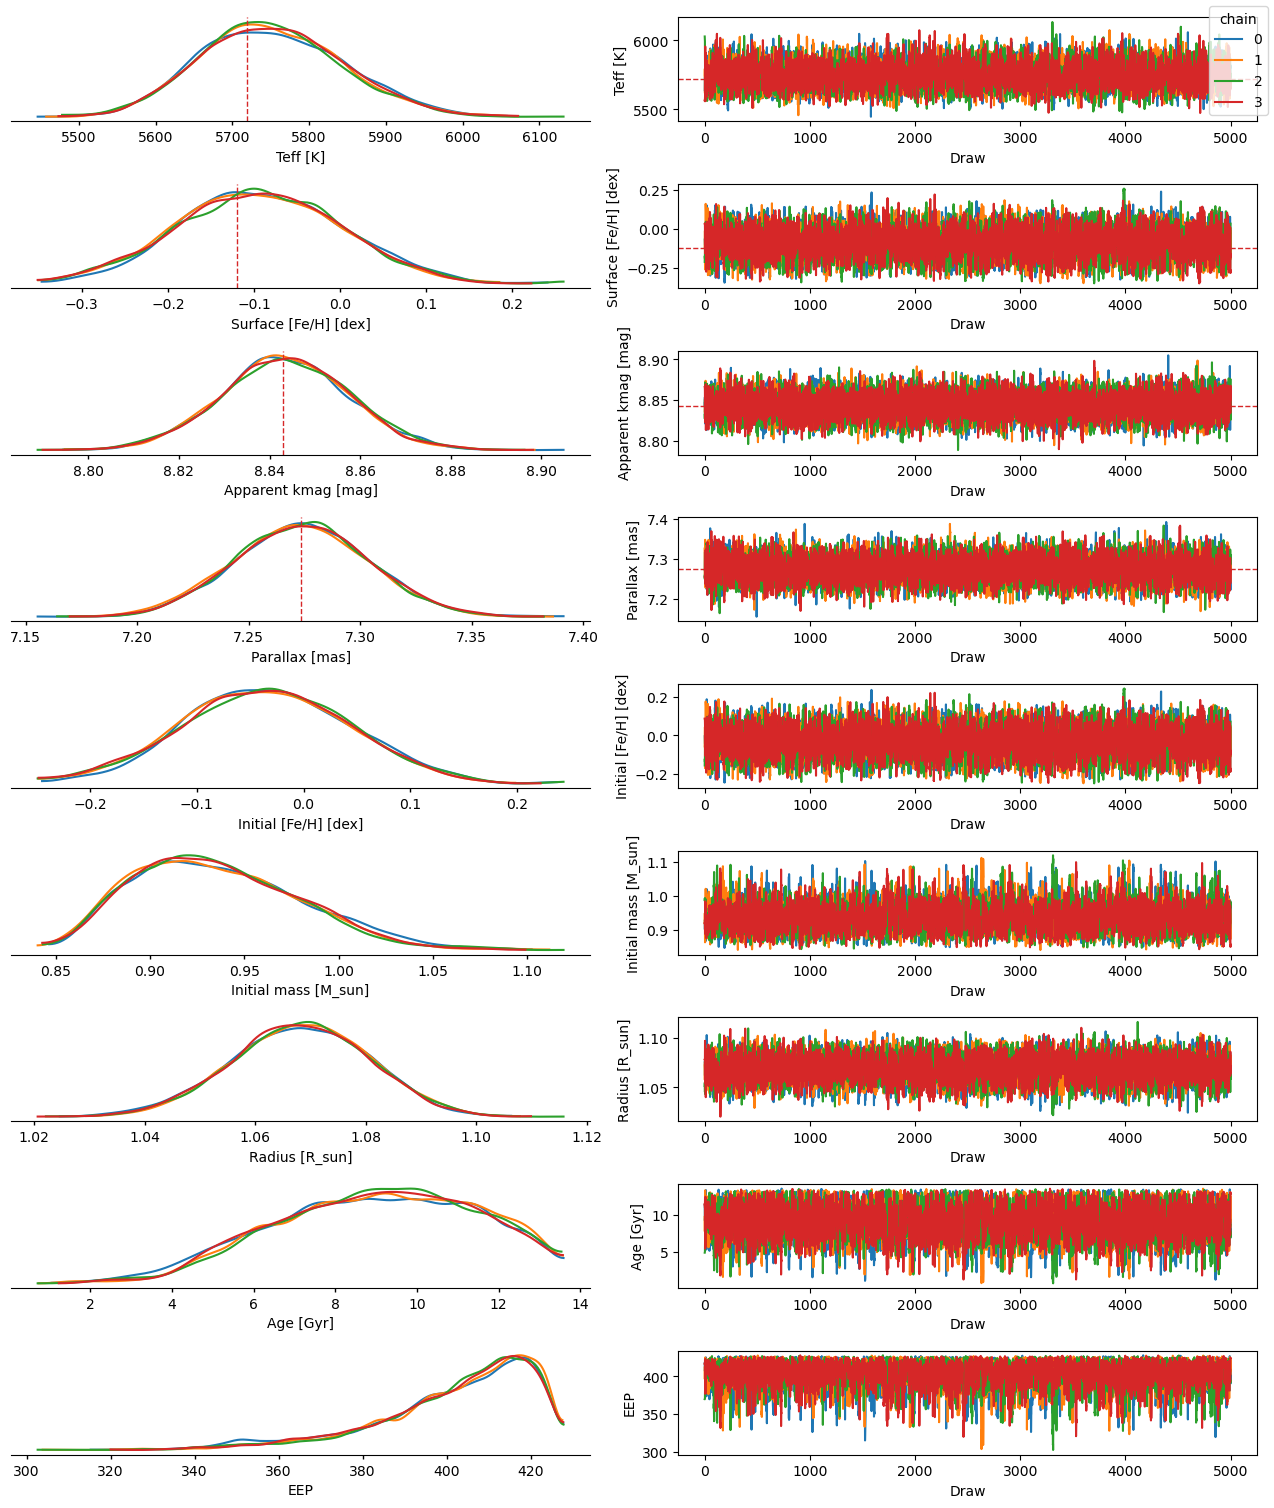

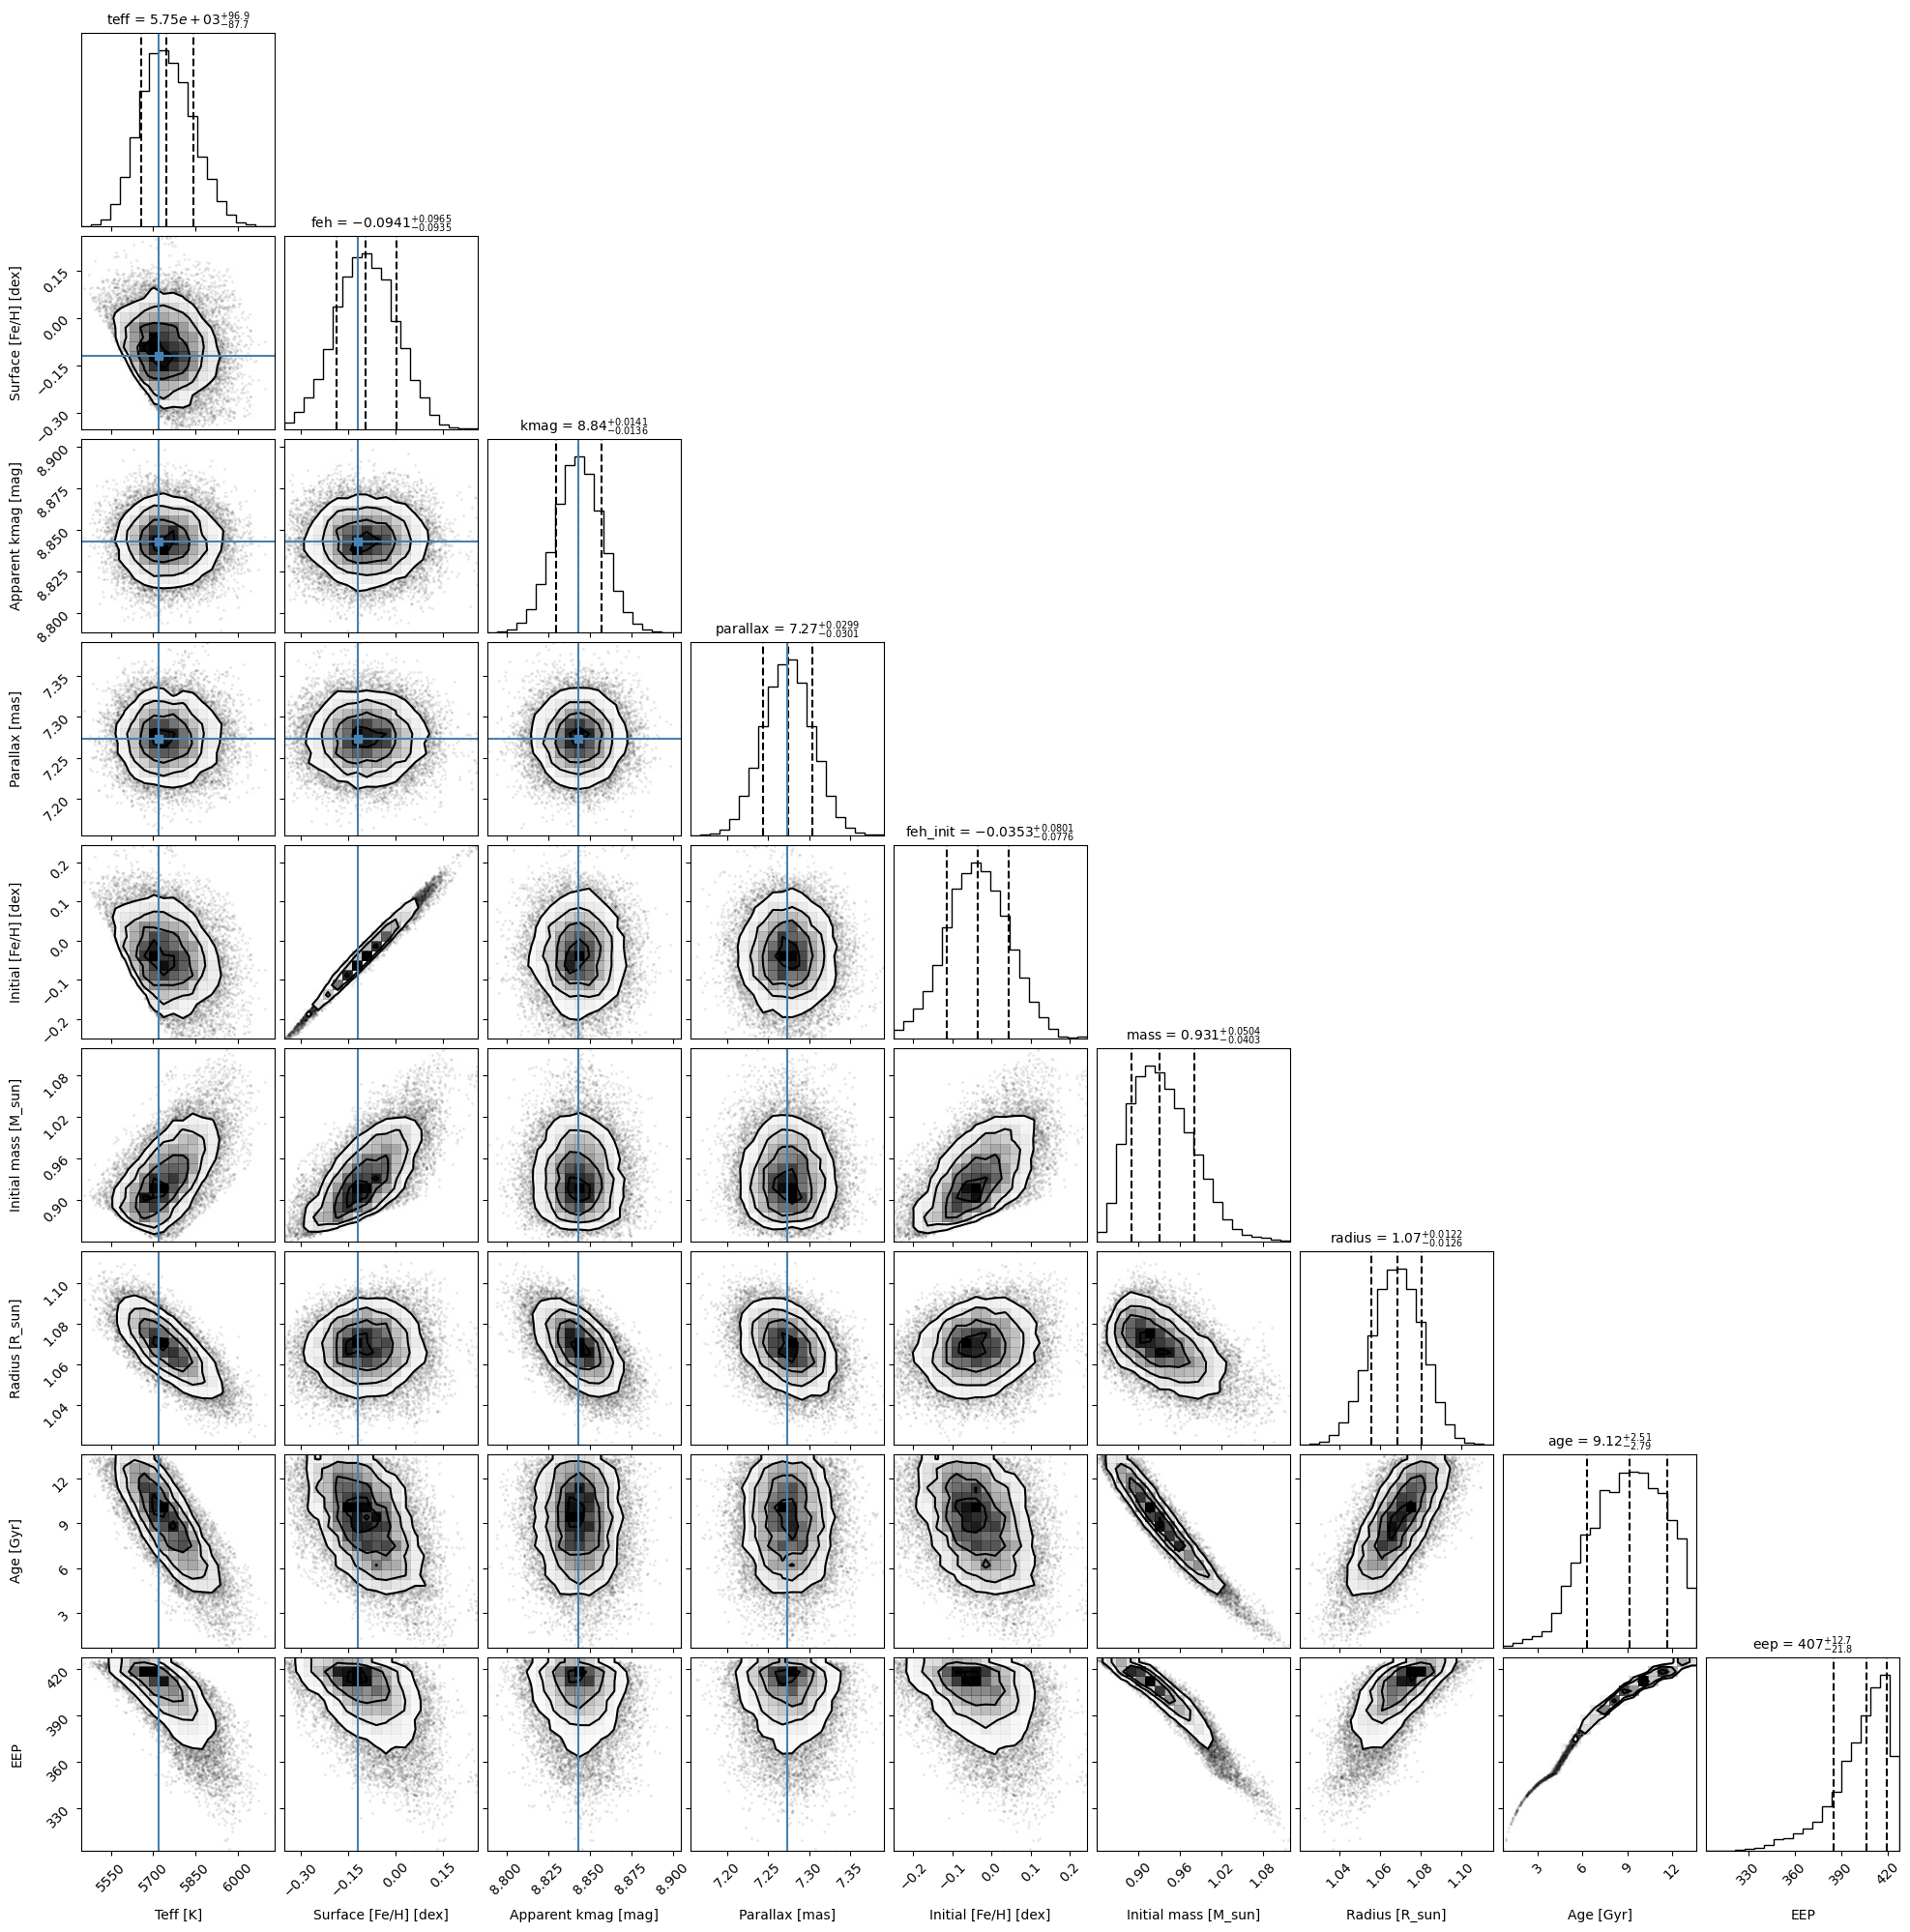

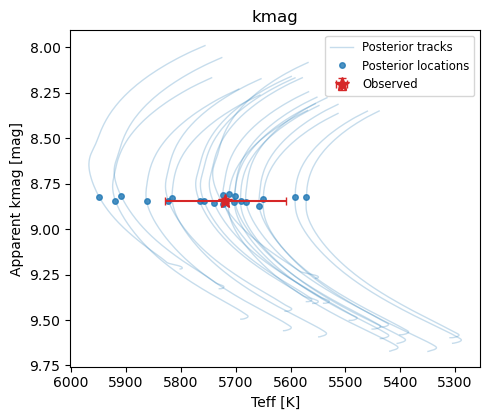

In [7]:
outkeys = [*observations, "feh_init", "mass", "radius", "age", "eep"]
figures = mf.plot_diagnostics(idata, keys=outkeys, output_dir=result_dir, overwrite=True)

## Optional: nested sampling

The following section fits the same model with MultiNest.
This requires `pymultinest` and the native MultiNest library in addition to
`numpyro-inferutils`; see the [backend guide](../../docs/mistfit.md#optional-multinest-backend).


 MultiNest Warning: no resume file found, starting from scratch
 *****************************************************
 MultiNest v3.10
 Copyright Farhan Feroz & Mike Hobson
 Release Jul 2015

 no. of live points =  400
 dimensionality =    4
 *****************************************************

 MultiNest Warning!
 Parameter            4  of mode            1  is converging towards the edge of the prior.

 MultiNest Warning!
 Parameter            4  of mode            1  is converging towards the edge of the prior.

 MultiNest Warning!
 Parameter            4  of mode            1  is converging towards the edge of the prior.

 MultiNest Warning!
 Parameter            4  of mode            1  is converging towards the edge of the prior.

 MultiNest Warning!
 Parameter            4  of mode            1  is converging towards the edge of the prior.

 MultiNest Warning!
 Parameter            4  of mode            1  is converging towards the edge of the prior.

 MultiNest Warning!
 Pa

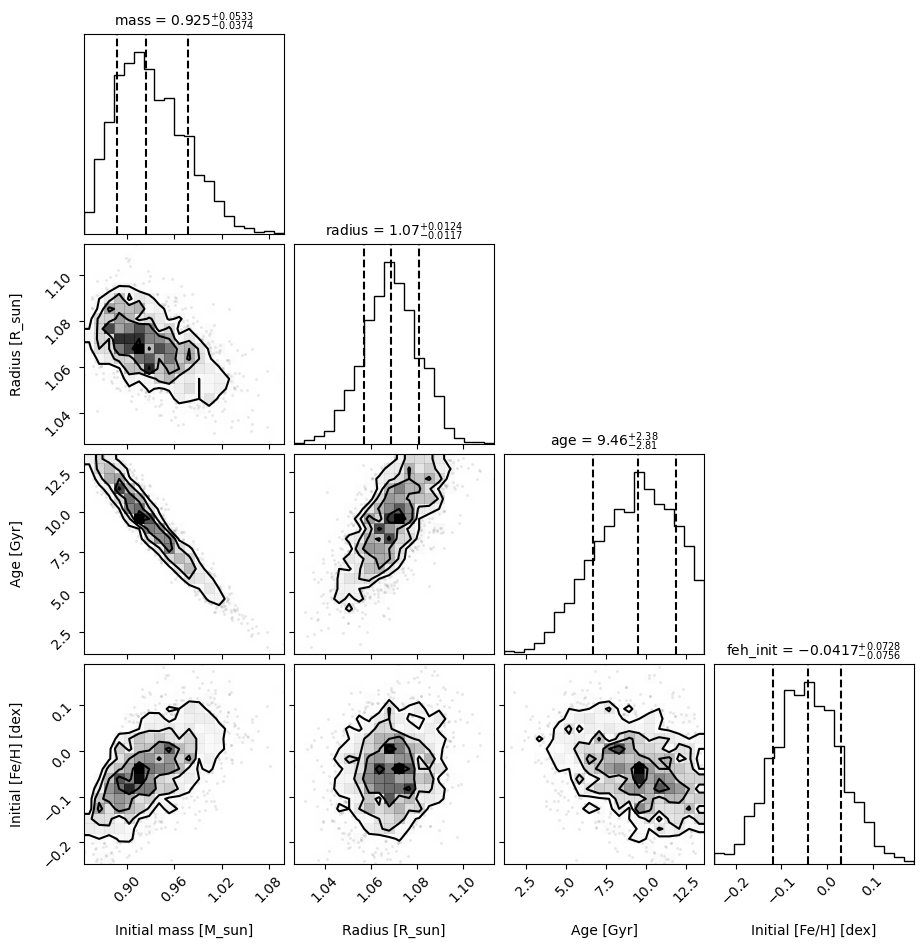

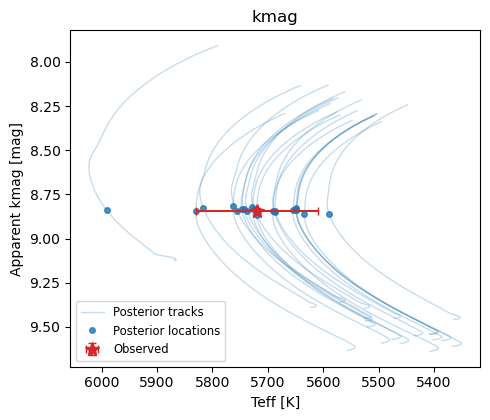

In [ ]:
run_nested_sampling = True

if run_nested_sampling:
    from jaxstar.mistfit import get_run_metadata

    # Keep the native MultiNest prefix short and relative to the working directory.
    mn_dir = Path("results/track_multinest")
    mn = mf.run_multinest(
        outputfiles_basename=str(mn_dir / "run1_"),
        model_kwargs=model_kwargs,
        n_live_points=400,
        resume=False,
    )
    mn_idata = mf.to_inference_data(mn)
    mf.save_result(mn_idata, mn_dir, overwrite=True)
    mn_figures = mf.plot_diagnostics(
        mn_idata, output_dir=mn_dir,
        keys=("mass", "radius", "age", "feh_init"), overwrite=True,
    )
    print(get_run_metadata(mn_idata)["evidence"])
